# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import galsim

from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology

from scipy.stats import norm,multivariate_normal
from nautilus import Prior

import astropy.units as u
from astropy.cosmology import FlatLambdaCDM, Planck18 
from astropy import constants
from astropy import table

from scipy import integrate
import xlensing
import cluster_toolkit
import glob
import tqdm

Lookup table loaded!


In [2]:
datadir = "/home/andre/data/TNG_SIMULATED_SHEAR_CATALOGS"

## Defining Units and scalings between codes

In [3]:
Mhalo = 1e14
conc = 5.
zhalo = .3
zsource = 1.0
OmegaM = 0.3
OmegaL = 0.7
astropy_cosmo = Planck18#FlatLambdaCDM(H0=.7,Om0=OmegaM)
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [4]:
radii_mpc = np.linspace(0.01,10,1000)
ang_radii = np.degrees(radii_mpc/astropy_cosmo.angular_diameter_distance(.3).value)*3600
positions = [galsim.PositionD(0.,sep) for sep in ang_radii]

In [5]:
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

In [6]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmo (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, astropy_cosmo)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2e}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, astropy_cosmo)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2e}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2.02e+09 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2.48e+09 solMass / kpc2


In [7]:
def deltasigma_nfw_colossus(colossus_profile,z_source,r):
    z_lens = zhalo
    Sigma_bar = 2*(integrate.quad(lambda r : colossus_profile.surfaceDensity(r)*r,1e-8,r,epsabs=0.,limit=150))[0]/r**2
    Sigma = colossus_profile.surfaceDensity(r)
    deltasigma = Sigma_bar - Sigma
    return deltasigma/1e6

In [8]:
scrit=critical_surface_density(z_l=0.3, z_s=1.0, cosmo=astropy_cosmo).value/1e6

In [9]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

In [10]:
from cluster_toolkit import deltasigma

Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(
    R=radii_mpc,
    Rs=radii_mpc,
    Sigma=Sigma_nfw,
    mass=Mhalo,
    concentration=conc,
    Omega_m=OmegaM,
    delta=200,
)

In [11]:
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_xlensing = xlensing_res['NFW Signal']

In [12]:
delta_sigma_galsim = shears_galsim[:,0]*scrit

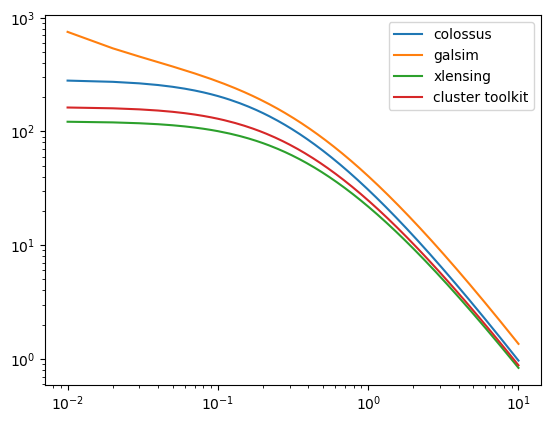

In [13]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
plt.yscale('log')
plt.legend()

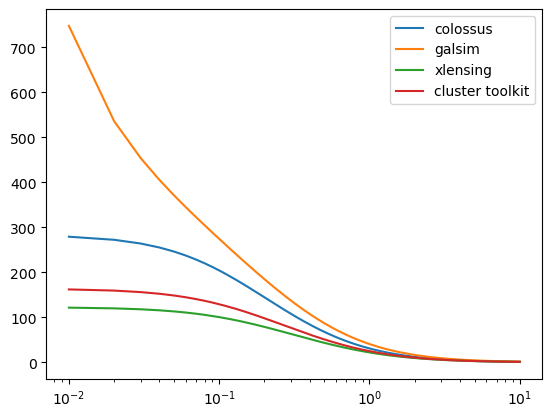

In [14]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
#plt.yscale('log')
plt.legend()

In [15]:
radii_mpc = np.logspace(-2,1,10)

In [16]:
%%timeit
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

31.7 ms ± 651 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

71 ms ± 924 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
%%timeit
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)

6.23 ms ± 107 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
%%timeit
Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(R=radii_mpc,Rs=radii_mpc,Sigma=Sigma_nfw,mass=Mhalo,concentration=conc,Omega_m=OmegaM,delta=200,
)

19.9 μs ± 211 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Generating a field of galaxies

In [20]:
n_gal_factor = 100
max_radius = 8
nbar = 30 
cluster = [0.,0.,.3,1e14,5.] 

In [21]:
def simcluster(gal_density,total_radius,z_range,cluster,shape_noise,seed=31415):
    cat = xlensing.sims.make_simple_random_cat(
        density=gal_density, 
        width_rad=total_radius/xlensing.cosmo.DA(0,0.3), 
        zrange=z_range, 
        shape_noise=shape_noise,
        seed=seed
    ).T
    cat = xlensing.sims.apply_NFW_shear_region(cluster,cat)
    cat = table.Table(cat,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])
    return cat 

In [22]:
cluster_test = simcluster(gal_density=nbar,total_radius=max_radius,z_range=[.3,2.],cluster=cluster,shape_noise=0.25/np.sqrt(n_gal_factor),seed=None)

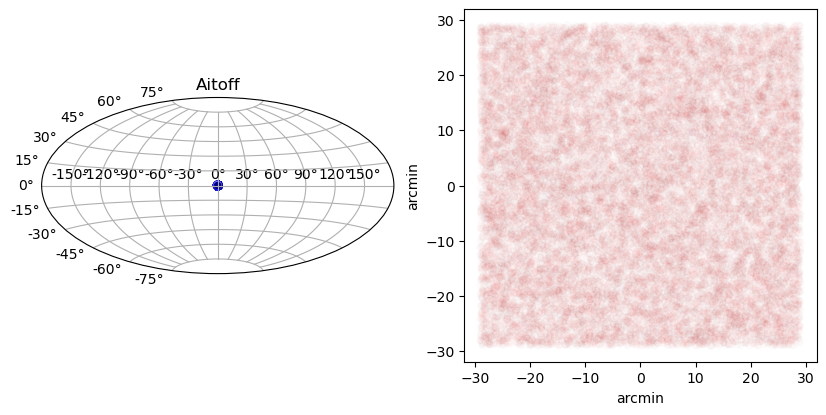

In [23]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
ellip = np.sqrt(cluster_test['e1']**2+ cluster_test['e2']**2)
plt.scatter(cluster_test['ra'],cluster_test['dec'],s=(cluster_test['z']+1)*10,c=ellip,cmap='seismic')
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(cluster_test['ra'])*60,np.degrees(cluster_test['dec'])*60,s=(cluster_test['z']+1)*10,c=np.log10(ellip),cmap='seismic',alpha=.01)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [24]:
galaxy_catalog = {}
galaxy_catalog['RA'] = cluster_test['ra']
galaxy_catalog['DEC'] = cluster_test['dec']
galaxy_catalog['ZPHOT'] = cluster_test['z']
galaxy_catalog['E1'] = cluster_test['e1']
galaxy_catalog['E2'] = cluster_test['e2']
galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
galaxy_catalog = table.Table(galaxy_catalog)

## Fitting

In [25]:
clusters = table.Table([[0],[0],[0.3]],names=['RA','DEC', 'Z'])

In [26]:
sr_RA = np.array(galaxy_catalog['RA'])
sr_DEC= np.array(galaxy_catalog['DEC'])
sr_z  = np.array(galaxy_catalog['ZPHOT'])
sr_E1 = np.array(galaxy_catalog['E1'])
sr_E2 = np.array(galaxy_catalog['E2'])
sr_W = np.array(galaxy_catalog['WEIGHT'])
sr_M = np.array(galaxy_catalog['M'])

clusters['INDEX'] = np.array(range(len(clusters)))

In [27]:
galaxy_catalog

RA,DEC,ZPHOT,E1,E2,WEIGHT,M
float64,float64,float64,float64,float64,float64,float64
-0.00819633616488133,-0.008071924397117075,1.477850255757693,-0.03135558490735041,-0.018790063800143593,1.0,0.0
-0.0018048418500463655,0.00820599506655738,1.8986944976371378,-0.0219646982489779,-0.0026404911381617737,1.0,0.0
-0.006513707668305978,-0.00811850796654423,0.33806245574279414,-0.0017270518158836955,-0.03732737322439072,1.0,0.0
-0.008256565106238905,0.00429763197437087,0.7349506830266028,-0.011961002642576189,-0.02278978800859164,1.0,0.0
0.007046755818814157,-0.006789839326015926,1.0060897440174001,0.006467405674592933,-0.054216446778442784,1.0,0.0
-0.005244642649341444,-0.0073724234516828815,1.011753399004779,0.0005790731457210375,0.023842257590559055,1.0,0.0
-0.005216840800155784,0.004536655552045304,0.3234656502788213,0.005932946322562976,0.0009033888693900559,1.0,0.0
0.00835356320954051,0.007791800849616394,1.2308187990100925,-0.055889875545344046,0.003773573314663783,1.0,0.0
-0.0046483583513151384,0.004392599031251261,1.922307589089097,-0.00448735102112505,0.003160329849722245,1.0,0.0


In [28]:
cl_RA=np.array(clusters['RA'])
cl_DEC= np.array(clusters['DEC'])
cl_z= np.array(clusters['Z'])
cl = np.array([cl_RA,cl_DEC,cl_z]).T

In [29]:
#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

# you can use whatever, but your machine core count is usually a good choice (although maybe not the best)
pool = Pool(cpu_count()) 

#We get a partial function with a constant galaxy catalogue to iterate with clusters.
survey_lensing = partial(
    xlensing.data.lensfit_cluster_lensing,
    sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
    radius=10.
)

In [30]:
clz = zip(cl_RA,cl_DEC,cl_z)
clzlist = [x for x in clz]

In [31]:
results = pool.map(survey_lensing, clzlist)
pool.close()

## Stacking

In [32]:
radii = np.logspace(-.6,.6,8)
N = len(radii)
bins_lims = np.logspace(np.log10(radii[0])+(np.log10(radii[0])-np.log10(radii[1]))/2,
                        np.log10(radii[N-1])-(np.log10(radii[0])-np.log10(radii[1]))/2,N+1)
bins_lims = np.array([[bins_lims[i],bins_lims[i+1]] for i in range(N)])
bins_lims #in Mpc/h

array([[0.2061986 , 0.30599497],
       [0.30599497, 0.45409096],
       [0.45409096, 0.67386272],
       [0.67386272, 1.        ],
       [1.        , 1.48398179],
       [1.48398179, 2.20220195],
       [2.20220195, 3.26802759],
       [3.26802759, 4.84969343]])

In [33]:
stick = [clusters]

In [34]:
Nboot=1000
import time
stick_results = []
for stake in stick:
    t = time.time()
    clusterbkgs = []
    for index in range(1):
        Sigma_crit = np.array(results[0]['Critical Density'])
        e_t = np.array(results[0]['Tangential Shear'])
        e_x = np.array(results[0]['Critical Density'])
        W = np.array(results[0]['Weights'])
        M = np.array(results[0]['Mult. Bias'])
        R = np.array(results[0]['Radial Distance'])
        clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))
    print(len(clusterbkgs))
    #sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stack(clusterbkgs,bins_lims,Nboot)
    #stick_results.append( ( sigmas, sigmas_cov, xigmas, xigmas_cov) )
    #print("Done in " + str(time.time()-t) + " seconds.")

1


In [35]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[12, 31, 72, 187, 344, 741, 1620, 3647]

Single cluster:
Separating galaxies per radial bin...


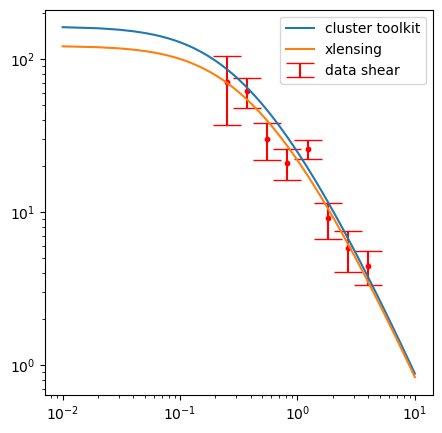

In [36]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data shear')
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Fitting a single cluster

In [37]:
from scipy.stats import truncnorm


loc = 5
a_trunc = .1
b_trunc = 10
scale = 4
a, b = (a_trunc - loc) / scale, (b_trunc - loc) / scale
prior_c= truncnorm(a=a,b=b,loc=loc,scale=scale)



In [50]:
prior = Prior()
prior.add_parameter('logMhalo', dist=norm(12,4))



prior.add_parameter('conc', dist=prior_c)

def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov)
    

In [51]:
param_test = {
    'logMhalo': 14,
    'conc': 5,   
}
model_wrapper(param_test)

array([69.97083208, 54.36091931, 39.56197263, 27.01160184, 17.39228288,
       10.63781847,  6.22950287,  3.51879972])

In [52]:
loglike(param_test)

np.float64(-24.71748470142939)

In [53]:
from nautilus import Sampler

sampler = Sampler(prior, loglike, n_live=1000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 14     | 1        | 4        | 18795    | N/A    | 10035 | -29.86   


np.True_

In [54]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 14.0022 - 0.6374 + 0.0539
conc: 4.3264 - 1.0979 + 2.2008


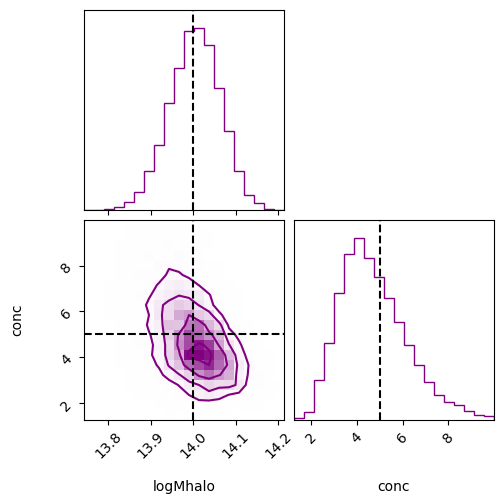

In [55]:
import corner



figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [56]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████████████| 300/300 [00:20<00:00, 14.65it/s]


In [57]:
xlensing_true=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_true = xlensing_true['NFW Signal']

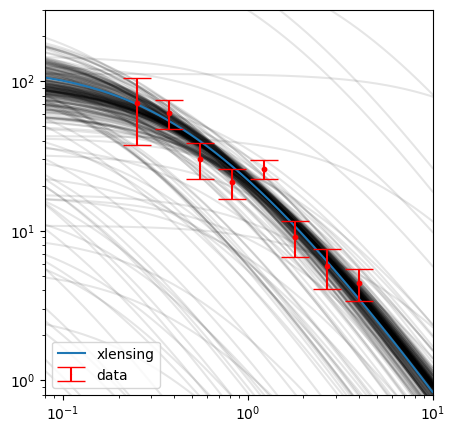

In [58]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Is it biased?

In [59]:
clusters= np.load("clusters.npy",allow_pickle=True)

In [60]:
galaxy_catalogs = []

for cluster_test in clusters:
    galaxy_catalog = {}
    galaxy_catalog['RA'] = cluster_test['ra']
    galaxy_catalog['DEC'] = cluster_test['dec']
    galaxy_catalog['ZPHOT'] = cluster_test['z']
    galaxy_catalog['E1'] = cluster_test['e1']
    galaxy_catalog['E2'] = cluster_test['e2']
    galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
    galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
    galaxy_catalog = table.Table(galaxy_catalog)
    galaxy_catalogs += [galaxy_catalog]

In [61]:
sources_list = []
for galaxy_catalog in galaxy_catalogs:
    sr_RA = np.array(galaxy_catalog['RA'])
    sr_DEC= np.array(galaxy_catalog['DEC'])
    sr_z  = np.array(galaxy_catalog['ZPHOT'])
    sr_E1 = np.array(galaxy_catalog['E1'])
    sr_E2 = np.array(galaxy_catalog['E2'])
    sr_W = np.array(galaxy_catalog['WEIGHT'])
    sr_M = np.array(galaxy_catalog['M'])
    survey_lensing = partial(
        xlensing.data.lensfit_cluster_lensing,
        sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
        radius=10.
    )
    sources_list+=[(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M)]

In [62]:
survey_lensing = lambda sources : xlensing.data.lensfit_cluster_lensing(cluster=(cl_RA,cl_DEC,cl_z),sources=sources,radius=10.)

In [63]:
pool = Pool(cpu_count()) 
results=pool.map(survey_lensing,sources_list)
pool.close()
np.save("clusterbkgs.npy",results)

In [64]:
clusterbkgs = []
for result in results:
    Sigma_crit = np.array(result['Critical Density'])
    e_t = np.array(result['Tangential Shear'])
    e_x = np.array(result['Critical Density'])
    W = np.array(result['Weights'])
    M = np.array(result['Mult. Bias'])
    R = np.array(result['Radial Distance'])
    clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))

In [65]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[14, 28, 65, 146, 353, 750, 1643, 3586]

Single cluster:
Separating galaxies per radial bin...


In [66]:
sigmas_stack, boosts_stack, sigmas_cov_stack, xigmas_stack, xigmas_cov_stack = xlensing.data.stacked_signal(clusterbkgs,bins_lims,Nboot)

Total galaxies available per bin:
[   7408   16166   35315   78062  172186  378346  834077 1836923]



100%|███████████████████████████████████████████████████████████████████████████████| 1000/1000 [13:01<00:00,  1.28it/s]


In [67]:
singles = []
for bkg in tqdm.tqdm(clusterbkgs):
    sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single = xlensing.data.single_cluster([bkg],bins_lims,Nboot)
    singles +=[(sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single)]

  0%|                                                                                           | 0/500 [00:00<?, ?it/s]

Total galaxies available per bin:
[14, 28, 65, 146, 353, 750, 1643, 3586]

Single cluster:
Separating galaxies per radial bin...


  0%|▏                                                                                  | 1/500 [00:01<13:56,  1.68s/it]

Total galaxies available per bin:
[16, 29, 71, 179, 294, 781, 1614, 3702]

Single cluster:
Separating galaxies per radial bin...


  0%|▎                                                                                  | 2/500 [00:03<14:34,  1.76s/it]

...

100%|████████████████████████████████████████████████████████████████████████████████▋| 498/500 [13:10<00:03,  1.55s/it]

Total galaxies available per bin:
[13, 26, 70, 171, 300, 773, 1709, 3621]

Single cluster:
Separating galaxies per radial bin...


100%|████████████████████████████████████████████████████████████████████████████████▊| 499/500 [13:12<00:01,  1.55s/it]

Total galaxies available per bin:
[16, 30, 65, 133, 355, 779, 1614, 3766]

Single cluster:
Separating galaxies per radial bin...


100%|█████████████████████████████████████████████████████████████████████████████████| 500/500 [13:13<00:00,  1.59s/it]


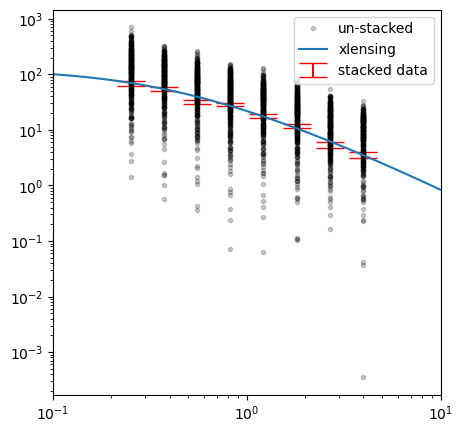

In [68]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='stacked data')

for index, single in enumerate(singles):
    if index==0:
        plt.plot(radii,single[0],'k.',alpha=.2,label='un-stacked')
    else:
        plt.plot(radii,single[0],'k.',alpha=.2)
plt.xlim([.1,1e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)

plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()

In [69]:
def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas_stack
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov_stack)
    

In [70]:
sampler = Sampler(prior, loglike, n_live=4000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 72450    | N/A    | 22258 | -23.57   


np.True_

In [71]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.9951 - 0.6755 + 0.0275
conc: 4.6474 - 0.8592 + 1.6251


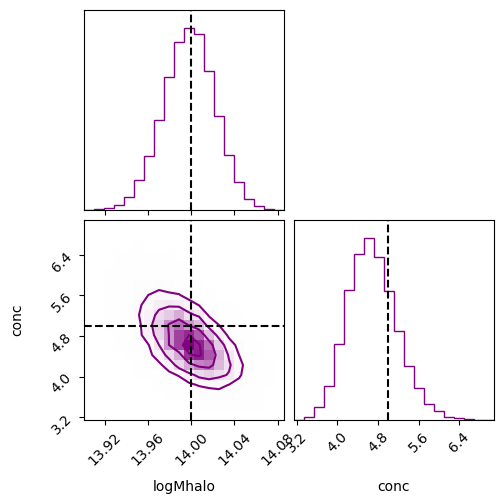

In [72]:
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [73]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████████████| 300/300 [00:20<00:00, 14.55it/s]


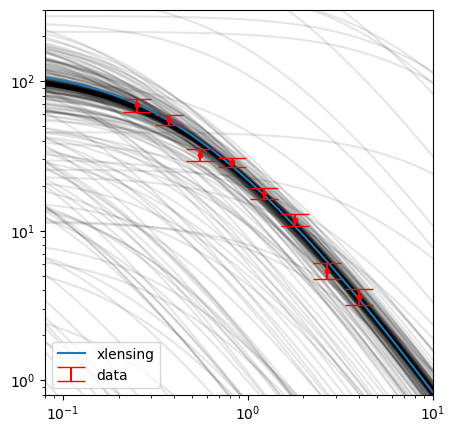

In [74]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()

In [75]:
single_fits = []
for single in tqdm.tqdm(singles):
    sigmas_single = single[0]
    sigmas_cov_single = single[1]
    def loglike(param_dict):
        model=model_wrapper(param_dict)
        data=sigmas_single
        return multivariate_normal.logpdf(model-data,cov=sigmas_cov_single)
    sampler = Sampler(prior, loglike, n_live=1000,pool=15)
    sampler.run(verbose=False)
    points, log_w, log_l = sampler.posterior()
    single_fits +=[(points, log_w, log_l)]
    del sampler
        

  3%|██▌                                                                             | 16/500 [06:17<3:14:18, 24.09s/it]/home/andre/miniconda3/lib/python3.12/site-packages/nautilus/bounds/neural.py:93: RankWarning: Polyfit may be poorly conditioned
  bound.score_predict_min = np.polyval(np.polyfit(
100%|███████████████████████████████████████████████████████████████████████████████| 500/500 [3:24:47<00:00, 24.57s/it]


In [76]:
allchains=np.vstack([single_fit[0] for single_fit in single_fits])

In [77]:
allweights=np.hstack([single_fit[1] for single_fit in single_fits])

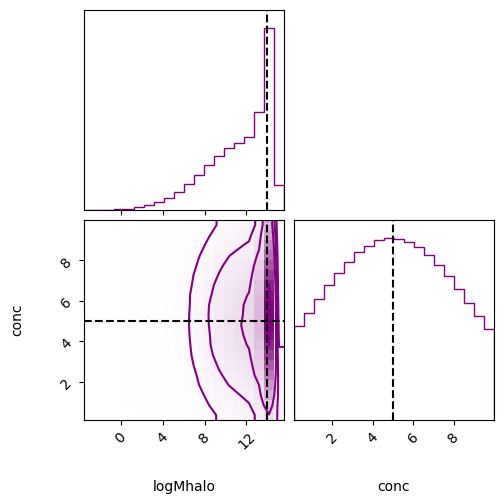

In [78]:
figure = corner.corner(
    allchains, weights=np.exp(allweights), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))
corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [79]:

mlo, mmd, mhi = np.percentile(allchains[:,0],[16,50,84])
clo, cmd, chi = np.percentile(allchains[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.5633 - 3.9610 + 1.0280
conc: 5.0140 - 3.1825 + 3.1512


In [80]:
def multi_like(param_dict):
    

SyntaxError: incomplete input (853190377.py, line 2)

In [ ]:

def weighted_quantile(values, quantiles, sample_weight=None, 
                      values_sorted=False, old_style=False):
    """ Very close to numpy.percentile, but supports weights.
    NOTE: quantiles should be in [0, 1]!
    :param values: numpy.array with data
    :param quantiles: array-like with many quantiles needed
    :param sample_weight: array-like of the same length as `array`
    :param values_sorted: bool, if True, then will avoid sorting of
        initial array
    :param old_style: if True, will correct output to be consistent
        with numpy.percentile.
    :return: numpy.array with computed quantiles.
    """
    values = np.array(values)
    quantiles = np.array(quantiles)
    if sample_weight is None:
        sample_weight = np.ones(len(values))
    sample_weight = np.array(sample_weight)
    assert np.all(quantiles >= 0) and np.all(quantiles <= 1), \
        'quantiles should be in [0, 1]'

    if not values_sorted:
        sorter = np.argsort(values)
        values = values[sorter]
        sample_weight = sample_weight[sorter]

    weighted_quantiles = np.cumsum(sample_weight) - 0.5 * sample_weight
    if old_style:
        # To be convenient with numpy.percentile
        weighted_quantiles -= weighted_quantiles[0]
        weighted_quantiles /= weighted_quantiles[-1]
    else:
        weighted_quantiles /= np.sum(sample_weight)
    return np.interp(quantiles, weighted_quantiles, values)